In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns 
import matplotlib.pyplot as plt 

In [ ]:
from sklearn.model_selection import train_test_split,cross_val_score
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score
from sklearn.preprocessing import LabelEncoder



In [ ]:
import joblib

In [ ]:
df=pd.read_csv("household_energy_consumption.csv")
df.head()

,Household_ID,Date,Energy_Consumption_kWh,Household_Size,Avg_Temperature_C,Has_AC,Peak_Hours_Usage_kWh
0,H00001,2025-04-01,8.4,4,17.8,No,3.2
1,H00001,2025-04-02,7.9,4,17.3,No,2.8
2,H00001,2025-04-03,9.2,4,18.6,No,3.0
3,H00001,2025-04-04,7.9,4,18.2,No,2.7
4,H00001,2025-04-05,9.6,4,11.9,No,3.2


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 90000 entries, 0 to 89999
Data columns (total 7 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Household_ID            90000 non-null  object 
 1   Date                    90000 non-null  object 
 2   Energy_Consumption_kWh  90000 non-null  float64
 3   Household_Size          90000 non-null  int64  
 4   Avg_Temperature_C       90000 non-null  float64
 5   Has_AC                  90000 non-null  object 
 6   Peak_Hours_Usage_kWh    90000 non-null  float64
dtypes: float64(3), int64(1), object(3)
memory usage: 4.8+ MB


In [ ]:
df.describe()

,Energy_Consumption_kWh,Household_Size,Avg_Temperature_C,Peak_Hours_Usage_kWh
count,90000.000000,90000.000000,90000.000000,90000.000000
mean,10.571988,3.487811,17.505802,4.319557
std,5.519494,1.709761,2.491621,2.531432
min,0.500000,1.000000,10.000000,0.200000
25%,6.000000,2.000000,15.800000,2.300000
50%,10.400000,3.000000,17.500000,4.000000
75%,14.800000,5.000000,19.200000,6.000000
max,20.000000,6.000000,25.000000,10.000000


In [ ]:
df['Energy_Consumption_kWh'] = df['Energy_Consumption_kWh'].fillna(df['Energy_Consumption_kWh'].mean())
df['Avg_Temperature_C'] = df['Avg_Temperature_C'].fillna(df['Avg_Temperature_C'].median())
df['Peak_Hours_Usage_kWh'] = df['Peak_Hours_Usage_kWh'].fillna(df['Peak_Hours_Usage_kWh'].mean())


In [ ]:

df['Has_AC'] = df['Has_AC'].fillna(df['Has_AC'].mode()[0])
df['Household_Size'] = df['Household_Size'].fillna(df['Household_Size'].median())


In [ ]:
df['Date'] = pd.to_datetime(df['Date'])
df['day_of_week'] = df['Date'].dt.dayofweek
df['month'] = df['Date'].dt.month
df['is_weekend'] = df['day_of_week'].isin([5,6]).astype(int)


In [ ]:

df['lag_1'] = df['Energy_Consumption_kWh'].shift(1)
df['lag_7'] = df['Energy_Consumption_kWh'].shift(7)



In [ ]:
df.isnull().sum()

Household_ID              0
Date                      0
Energy_Consumption_kWh    0
Household_Size            0
Avg_Temperature_C         0
Has_AC                    0
Peak_Hours_Usage_kWh      0
day_of_week               0
month                     0
is_weekend                0
lag_1                     1
lag_7                     7
dtype: int64

In [ ]:
df.dropna(inplace=True)

In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
df['month'] = df['month'].fillna(df['month'].mode()[0])


In [ ]:
df.corr(numeric_only=True)

,Energy_Consumption_kWh,Household_Size,Avg_Temperature_C,Peak_Hours_Usage_kWh,day_of_week,month,is_weekend,lag_1,lag_7
Energy_Consumption_kWh,1.000000,0.893976,0.033314,0.967642,-0.000801,NaN,-0.000896,0.798360,0.000359
Household_Size,0.893976,1.000000,0.001007,0.794573,0.000010,NaN,0.000006,0.766340,0.000897
Avg_Temperature_C,0.033314,0.001007,1.000000,0.031719,-0.001156,NaN,0.000860,0.001727,0.005098
Peak_Hours_Usage_kWh,0.967642,0.794573,0.031719,1.000000,0.000034,NaN,-0.000371,0.778661,0.000181
day_of_week,-0.000801,0.000010,-0.001156,0.000034,1.000000,NaN,0.790570,0.000608,-0.000792
month,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
is_weekend,-0.000896,0.000006,0.000860,-0.000371,0.790570,NaN,1.000000,0.000486,-0.000892
lag_1,0.798360,0.766340,0.001727,0.778661,0.000608,NaN,0.000486,1.000000,0.132468
lag_7,0.000359,0.000897,0.005098,0.000181,-0.000792,NaN,-0.000892,0.132468,1.000000


In [ ]:
df["month"].astype('category')

7        4
8        4
9        4
10       4
11       4
        ..
89995    4
89996    4
89997    4
89998    4
89999    4
Name: month, Length: 89993, dtype: category
Categories (1, int32): [4]

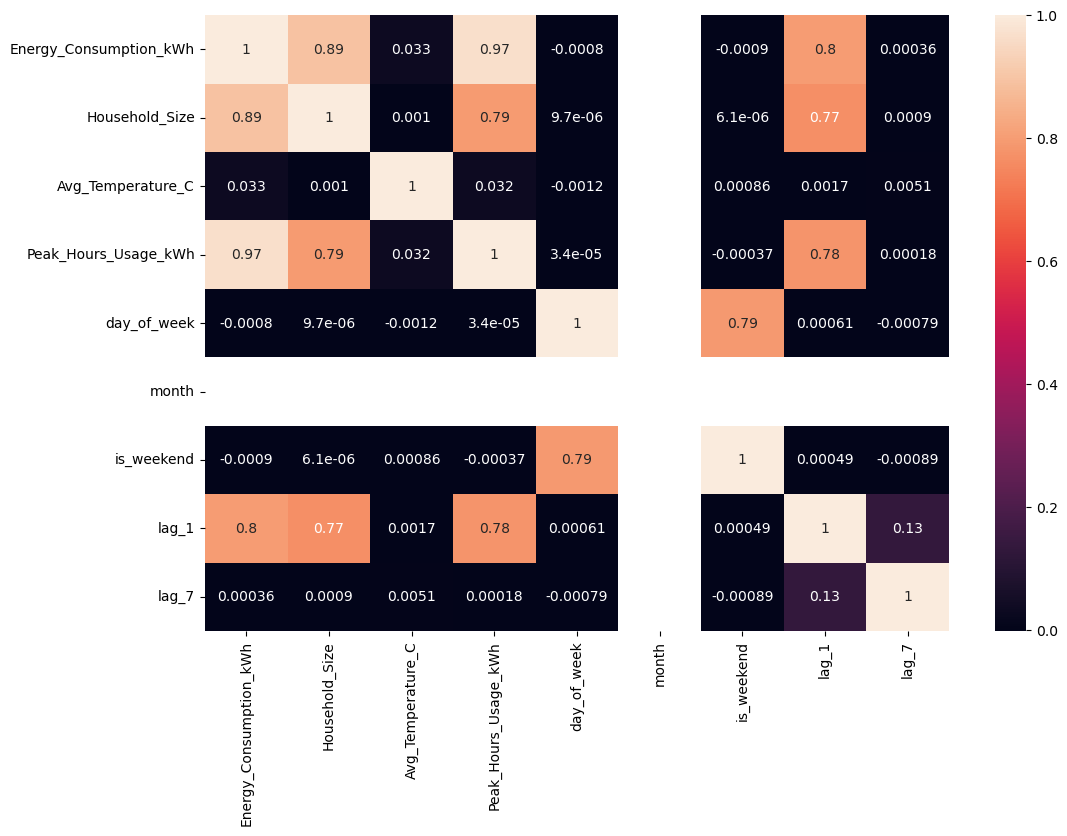

In [ ]:
plt.figure(figsize=(12, 8))
sns.heatmap(df.corr(numeric_only=True), annot=True)
plt.show()

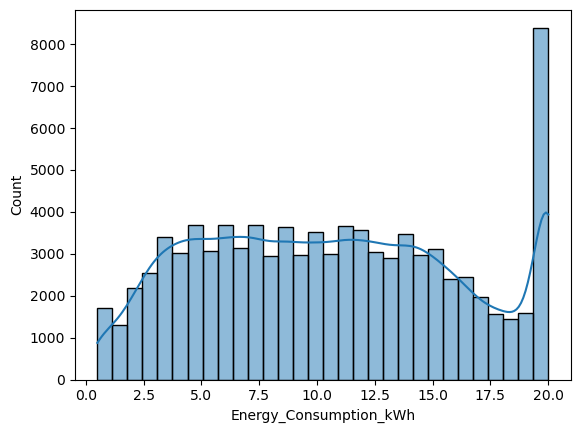

In [ ]:
sns.histplot(data=df, x='Energy_Consumption_kWh', bins=30, kde=True)
plt.show()

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 89993 entries, 7 to 89999
Data columns (total 12 columns):
 #   Column                  Non-Null Count  Dtype         
---  ------                  --------------  -----         
 0   Household_ID            89993 non-null  object        
 1   Date                    89993 non-null  datetime64[ns]
 2   Energy_Consumption_kWh  89993 non-null  float64       
 3   Household_Size          89993 non-null  int64         
 4   Avg_Temperature_C       89993 non-null  float64       
 5   Has_AC                  89993 non-null  object        
 6   Peak_Hours_Usage_kWh    89993 non-null  float64       
 7   day_of_week             89993 non-null  int32         
 8   month                   89993 non-null  int32         
 9   is_weekend              89993 non-null  int64         
 10  lag_1                   89993 non-null  float64       
 11  lag_7                   89993 non-null  float64       
dtypes: datetime64[ns](1), float64(5), int32(2), int64(2

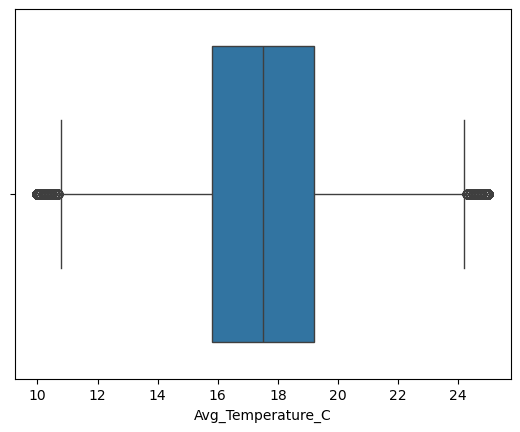

In [ ]:
sns.boxplot(data=df, x='Avg_Temperature_C')
plt.show()

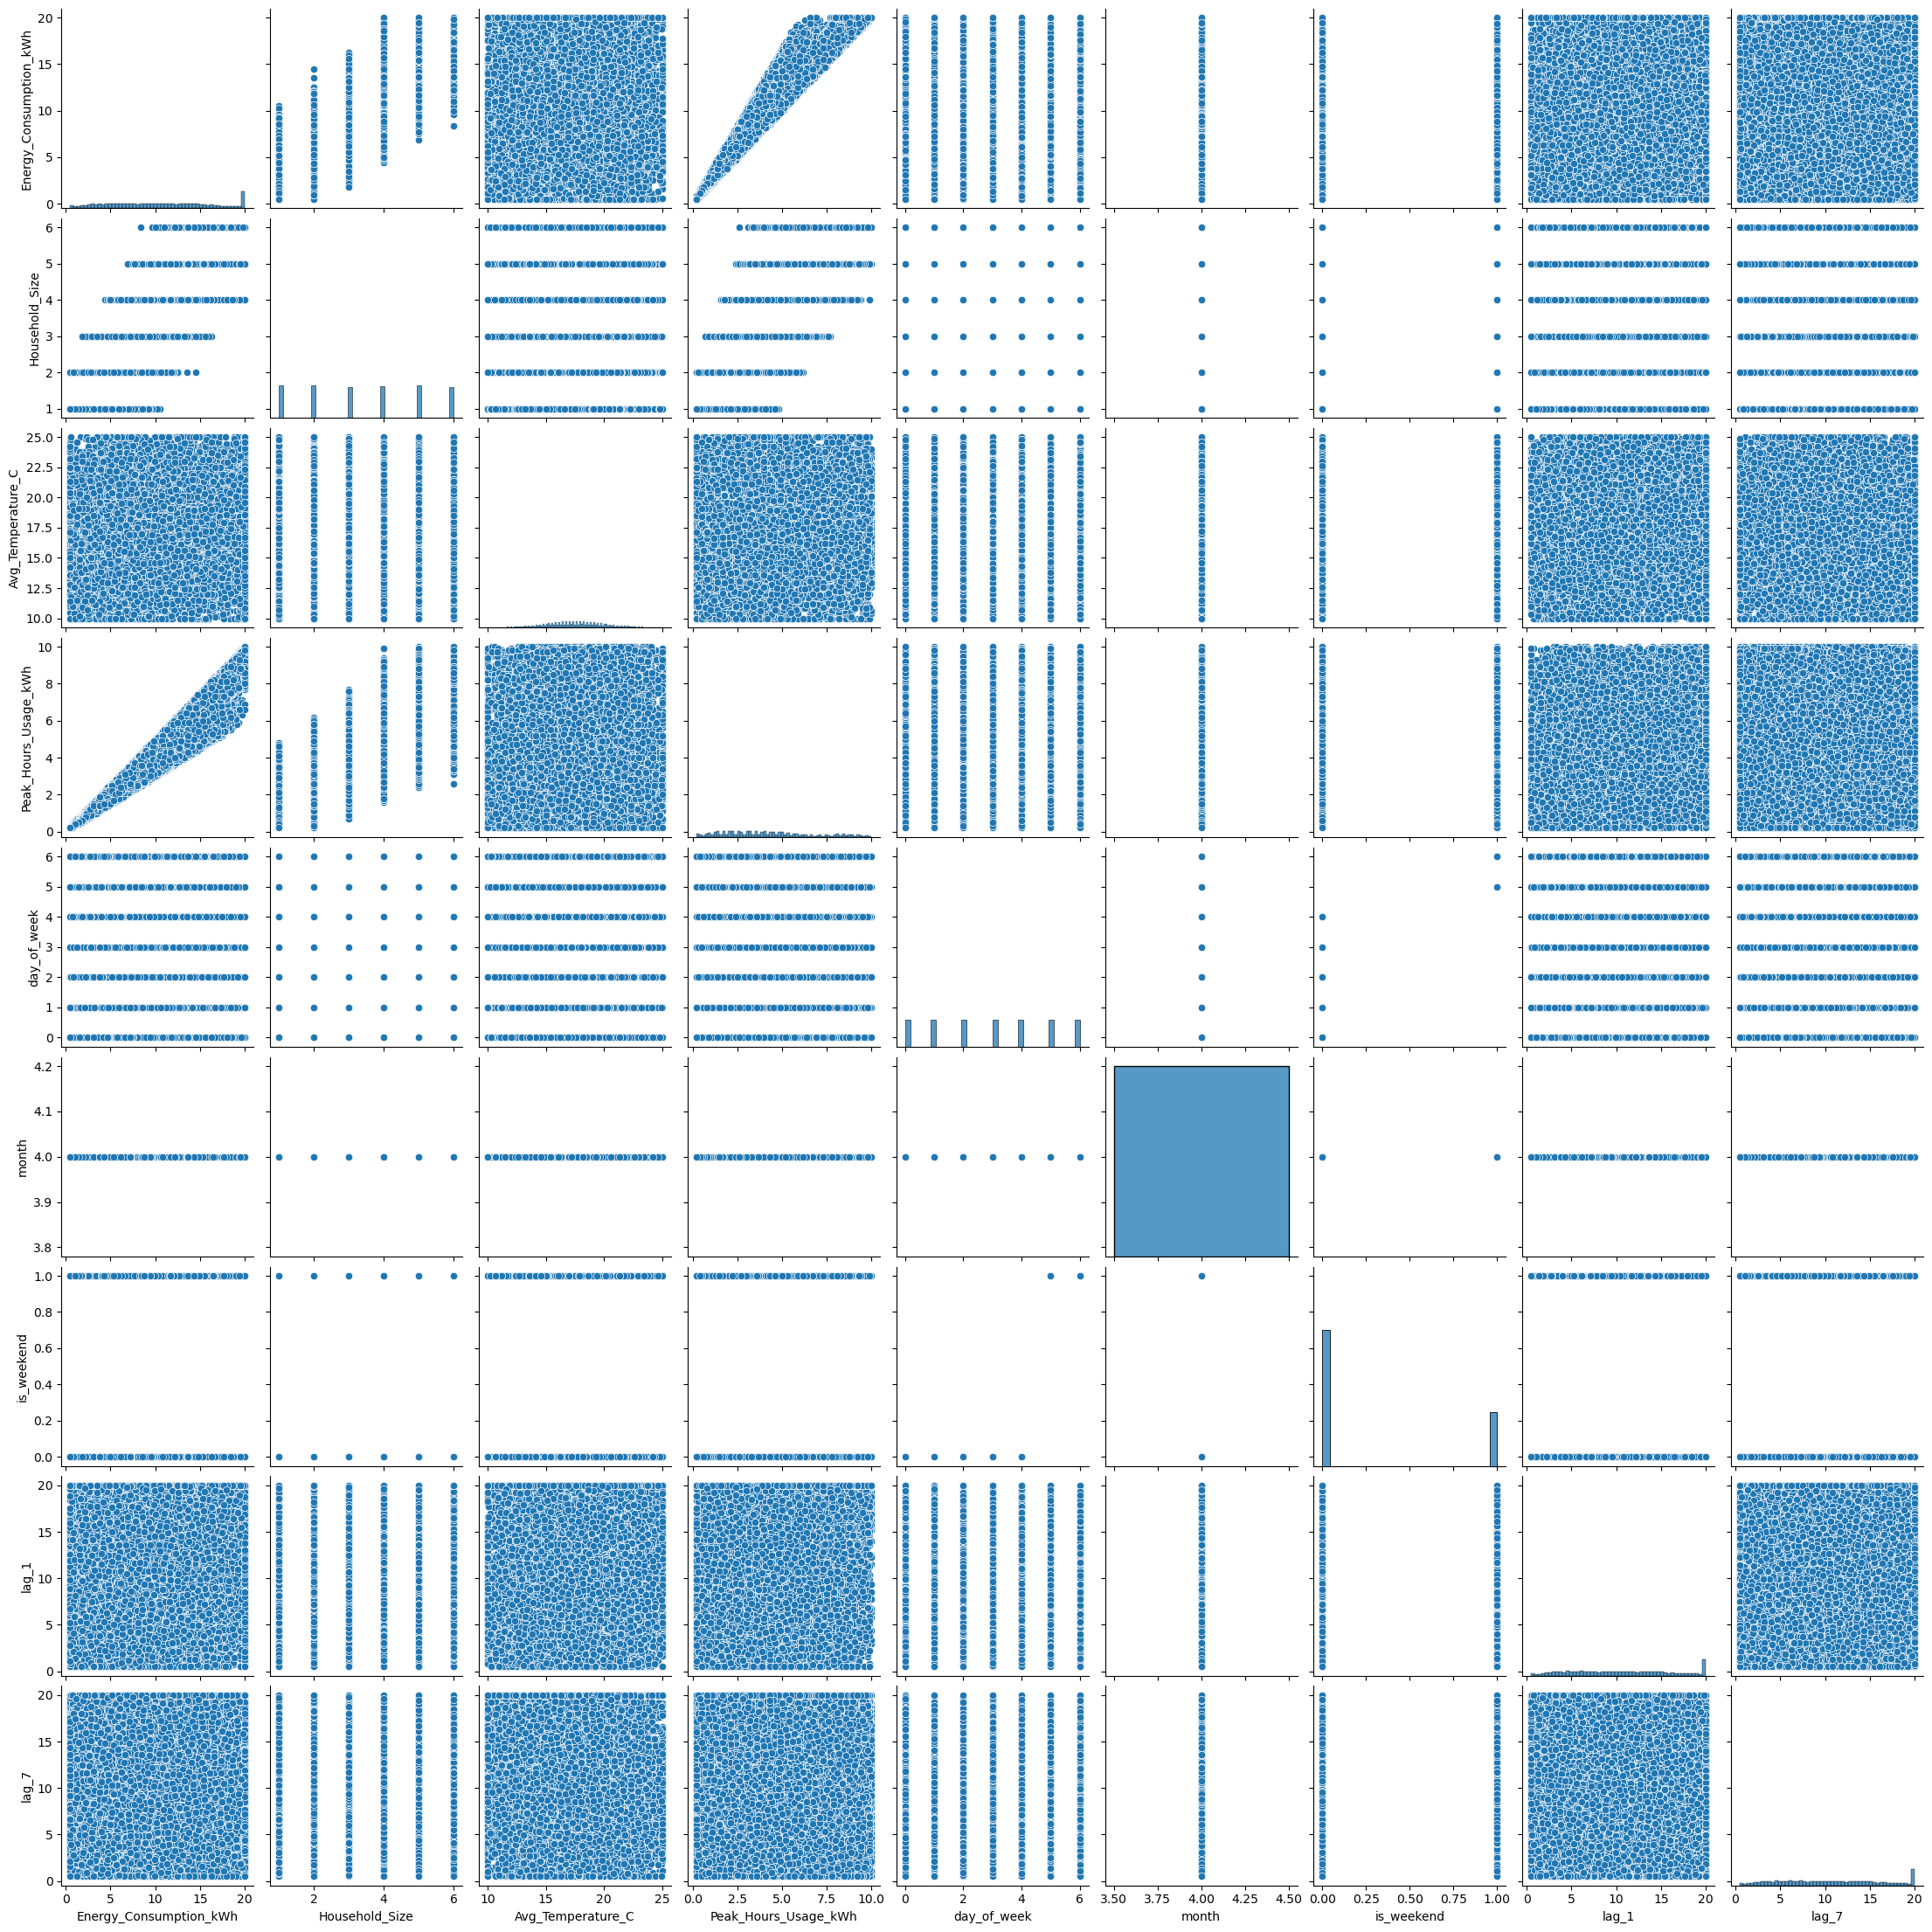

In [ ]:
sns.pairplot(df)
plt.show()

In [ ]:
df["Has_AC"]=df["Has_AC"].map({"Yes":1,"No":0})

In [ ]:

encoder = LabelEncoder()
df['Household_ID_encoded'] = encoder.fit_transform(df['Household_ID'])

In [ ]:

x= df[['Household_ID_encoded','Household_Size', 'Avg_Temperature_C', 'Has_AC',
        'Peak_Hours_Usage_kWh', 'day_of_week', 'month',
        'is_weekend', 'lag_1', 'lag_7']]

y = df['Energy_Consumption_kWh']
x.shape

(89993, 10)

In [ ]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)
x_train.shape

(71994, 10)

In [ ]:
x_test.shape

(17999, 10)

In [ ]:
model = LinearRegression()
model.fit(x_train, y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [ ]:
x.head()

,Household_ID_encoded,Household_Size,Avg_Temperature_C,Has_AC,Peak_Hours_Usage_kWh,day_of_week,month,is_weekend,lag_1,lag_7
7,0,5,18.0,0,4.2,1,4,0,9.1,8.4
8,0,5,12.7,0,4.9,2,4,0,11.9,7.9
9,0,5,19.7,0,4.5,3,4,0,12.4,9.2
10,0,5,18.4,0,4.1,4,4,0,12.1,7.9
11,0,5,19.6,0,5.1,5,4,1,11.1,9.6


In [ ]:
y_pred=model.predict(x_test)
y_pred

array([14.79767088,  8.31125701,  6.75516164, ..., 11.22567212,
        6.25597211, 17.59136751], shape=(17999,))

In [ ]:
comparison = pd.DataFrame({'Actual': y_test, 'Predicted': y_pred})
comparison

,Actual,Predicted
86018,16.3,14.797671
72640,9.0,8.311257
35485,6.4,6.755162
48007,11.8,11.382976
64657,15.1,13.762197
...,...,...
35052,12.5,14.485033
35156,12.3,13.451868
30797,10.1,11.225672
74011,5.4,6.255972


In [ ]:
coef=pd.DataFrame({'Features':x.columns, 'Coefficient': model.coef_})
coef

,Features,Coefficient
0,Household_ID_encoded,-0.000001
1,Household_Size,0.964960
2,Avg_Temperature_C,0.020243
3,Has_AC,-0.452582
4,Peak_Hours_Usage_kWh,1.651043
5,day_of_week,-0.002027
6,month,0.000000
7,is_weekend,0.001488
8,lag_1,-0.008184
9,lag_7,0.001357


In [ ]:
from sklearn.metrics import mean_squared_error, mean_absolute_error
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
print(rmse)

0.7991840724820607


In [ ]:
print("Mean consumption:", y.mean())
print("Std deviation:", y.std())
print("Min:", y.min(), "Max:", y.max())


Mean consumption: 10.5721478337204
Std deviation: 5.5196754263269305
Min: 0.5 Max: 20.0


In [ ]:
rmse = 0.7991840724820607  # your value

# Compare RMSE to mean and std deviation
print("RMSE as % of mean:", (rmse / y.mean()) * 100)
print("RMSE as % of std deviation:", (rmse / y.std()) * 100)


RMSE as % of mean: 7.559335009798318
RMSE as % of std deviation: 14.47882367630225


In [ ]:
from sklearn.metrics import mean_absolute_percentage_error

mape = mean_absolute_percentage_error(y_test, y_pred)
print("MAPE:", mape * 100, "%")


MAPE: 10.50773286215355 %


In [ ]:
r2_score(y_test, y_pred)

0.9791316575441577

In [ ]:

scores = cross_val_score(model, x, y, cv=5, scoring='r2')
print("Cross-validation R² scores:", scores)
print("Average R²:", np.mean(scores))


Cross-validation R² scores: [0.97934383 0.97950626 0.97941058 0.97931823 0.97976511]
Average R²: 0.9794688007049743


In [ ]:
# Step 11: Save model for dashboard use
joblib.dump(model, "energy_model.pkl")


['energy_model.pkl']

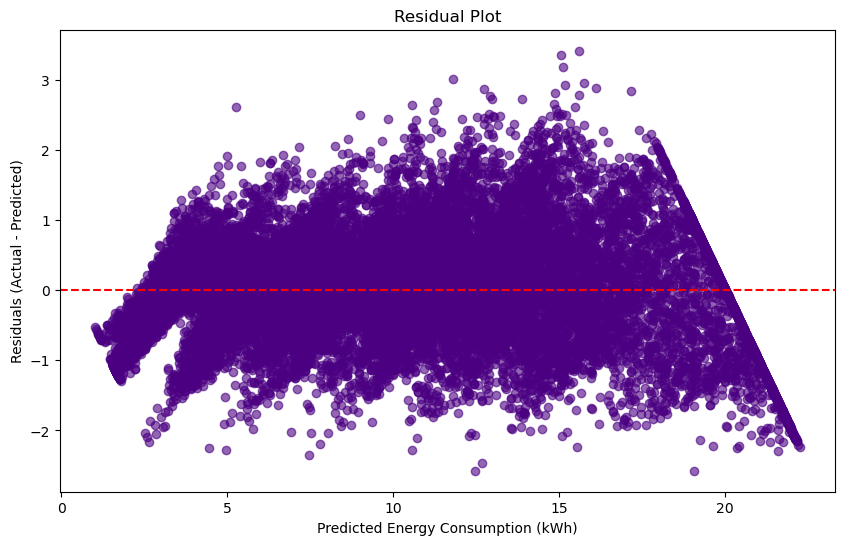

In [ ]:

residuals = y_test - y_pred
plt.figure(figsize=(10,6))
plt.scatter(y_pred, residuals, alpha=0.6, color='indigo')
plt.axhline(y=0, color='red', linestyle='--')  # zero error line
plt.xlabel("Predicted Energy Consumption (kWh)")
plt.ylabel("Residuals (Actual - Predicted)")
plt.title("Residual Plot")
plt.show()


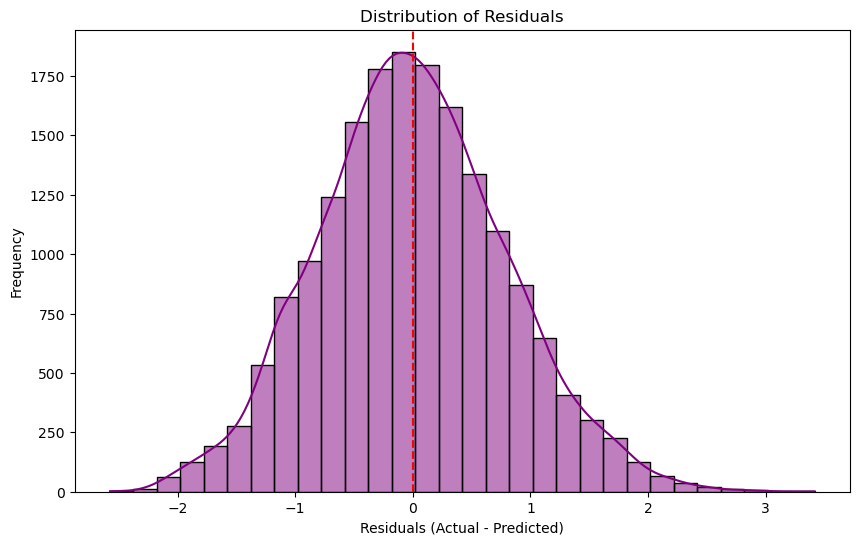

In [ ]:
plt.figure(figsize=(10,6))
sns.histplot(residuals, bins=30, kde=True, color='purple')
plt.axvline(x=0, color='red', linestyle='--')  # zero error line
plt.xlabel("Residuals (Actual - Predicted)")
plt.ylabel("Frequency")
plt.title("Distribution of Residuals")
plt.show()

In [41]:

from sklearn.ensemble import RandomForestRegressor
rf_model = RandomForestRegressor(
    n_estimators=200,      # number of trees
    max_depth=None,       
    random_state=42,     
    n_jobs=-1              # use all CPU cores
)

rf_model.fit(x_train, y_train)



,n_estimators,200
,criterion,'squared_error'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,1.0
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [42]:
y_pred_rf = rf_model.predict(x_test)
y_pred_rf

array([15.1395,  8.625 ,  6.7865, ..., 11.495 ,  5.068 , 17.392 ],
      shape=(17999,))

In [43]:

rmse_rf = np.sqrt(mean_squared_error(y_test, y_pred_rf))
r2_rf = r2_score(y_test, y_pred_rf)
mape_rf = mean_absolute_percentage_error(y_test, y_pred_rf)

print("Random Forest RMSE:", rmse_rf)
print("Random Forest R²:", r2_rf)
print("Random Forest MAPE:", mape_rf * 100, "%")

Random Forest RMSE: 0.6744757171826569
Random Forest R²: 0.9851362992764151
Random Forest MAPE: 5.565023182634884 %


In [44]:
print("Linear Regression RMSE:", rmse)
print("Random Forest RMSE:", rmse_rf)
print("R2 Comparison")
print("Random Forest R²:", r2_rf)
print("Linear Regression R²:", r2_score(y_test, y_pred))

Linear Regression RMSE: 0.7991840724820607
Random Forest RMSE: 0.6744757171826569
R2 Comparison
Random Forest R²: 0.9851362992764151
Linear Regression R²: 0.9791316575441577


In [45]:
importances = rf_model.feature_importances_
feature_names = x.columns

feat_imp = pd.DataFrame({'Feature': feature_names, 'Importance': importances})
feat_imp = feat_imp.sort_values(by='Importance', ascending=False)
print(feat_imp)

                Feature  Importance
4  Peak_Hours_Usage_kWh    0.941752
1        Household_Size    0.041739
3                Has_AC    0.003637
0  Household_ID_encoded    0.003250
2     Avg_Temperature_C    0.002967
9                 lag_7    0.002787
8                 lag_1    0.002643
5           day_of_week    0.001077
7            is_weekend    0.000150
6                 month    0.000000


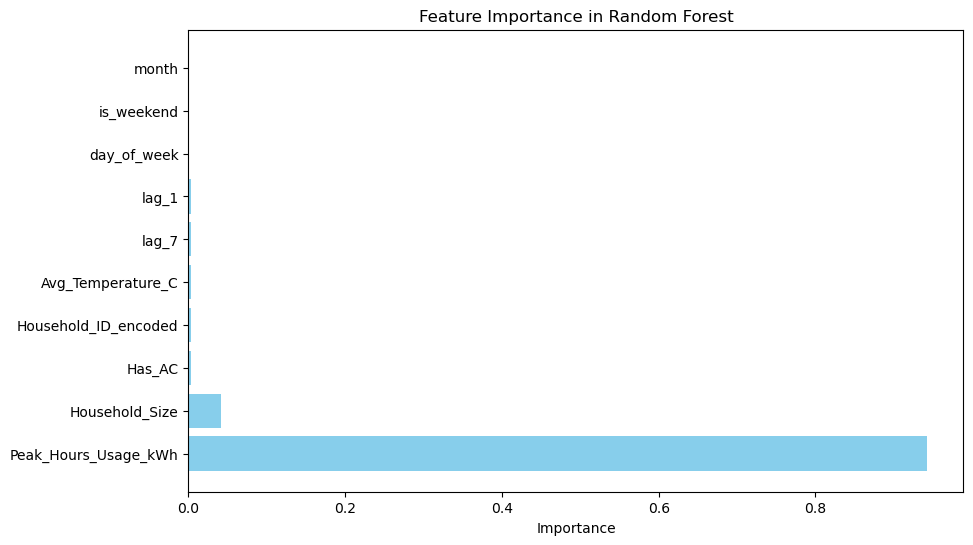

In [46]:

plt.figure(figsize=(10,6))
plt.barh(feat_imp['Feature'], feat_imp['Importance'], color='skyblue')
plt.xlabel("Importance")
plt.title("Feature Importance in Random Forest")
plt.show()


In [47]:
from sklearn.model_selection import RandomizedSearchCV
from sklearn.ensemble import RandomForestRegressor
import numpy as np

# Define parameter ranges
param_dist = {
    'n_estimators': np.arange(100, 500, 50),
    'max_depth': [None, 10, 20, 30, 40],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4],
    'max_features': ['sqrt', 'log2']
}

# Randomized search setup
random_search = RandomizedSearchCV(
    estimator=RandomForestRegressor(random_state=42, n_jobs=-1),
    param_distributions=param_dist,
    n_iter=15,          # number of random combinations to try
    cv=3,
    scoring='r2',
    random_state=42,
    n_jobs=-1,
    verbose=2
)

# Fit
random_search.fit(x_train, y_train)

# Best parameters from random search
print("Random Search Best Params:", random_search.best_params_)


Fitting 3 folds for each of 15 candidates, totalling 45 fits
Random Search Best Params: {'n_estimators': np.int64(350), 'min_samples_split': 10, 'min_samples_leaf': 1, 'max_features': 'sqrt', 'max_depth': 30}


In [48]:
from sklearn.model_selection import GridSearchCV

# Example: refine around best params
best_params = random_search.best_params_

param_grid = {
    'n_estimators': [best_params['n_estimators']-50, best_params['n_estimators'], best_params['n_estimators']+50],
    'max_depth': [best_params['max_depth'], best_params['max_depth']+10],
    'min_samples_split': [best_params['min_samples_split'], best_params['min_samples_split']+2],
    'min_samples_leaf': [best_params['min_samples_leaf'], best_params['min_samples_leaf']+1],
    'max_features': [best_params['max_features']]
}

grid_search = GridSearchCV(
    estimator=RandomForestRegressor(random_state=42, n_jobs=-1),
    param_grid=param_grid,
    cv=3,
    scoring='r2',
    n_jobs=-1,
    verbose=2
)

grid_search.fit(x_train, y_train)

print("Grid Search Best Params:", grid_search.best_params_)
print("Grid Search Best R²:", grid_search.best_score_)


Fitting 3 folds for each of 24 candidates, totalling 72 fits
Grid Search Best Params: {'max_depth': 30, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'min_samples_split': 10, 'n_estimators': np.int64(350)}
Grid Search Best R²: 0.9858941906096668


In [50]:
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_percentage_error
import numpy as np

best_rf = grid_search.best_estimator_
y_pred_best = best_rf.predict(x_test)

rmse_best = np.sqrt(mean_squared_error(y_test, y_pred_best))
r2_best = r2_score(y_test, y_pred_best)
mape_best = mean_absolute_percentage_error(y_test, y_pred_best)

print("Final RMSE:", rmse_best)
print("Final R²:", r2_best)
print("Final MAPE:", mape_best * 100, "%")


Final RMSE: 0.6637862746804409
Final R²: 0.9856037012204696
Final MAPE: 6.080291002583785 %


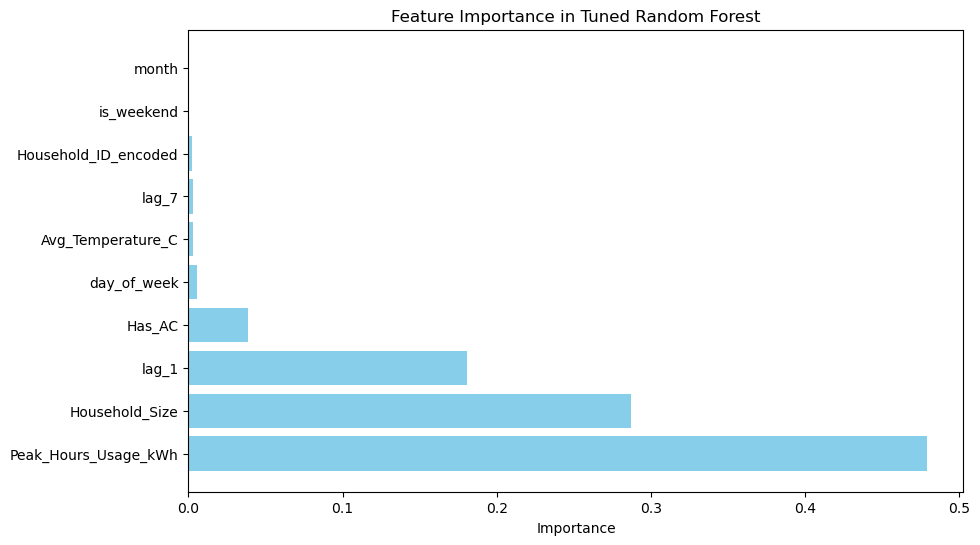

                Feature  Importance
4  Peak_Hours_Usage_kWh    0.478892
1        Household_Size    0.287436
8                 lag_1    0.180895
3                Has_AC    0.038818
5           day_of_week    0.005402
2     Avg_Temperature_C    0.002858
9                 lag_7    0.002784
0  Household_ID_encoded    0.002586
7            is_weekend    0.000329
6                 month    0.000000


In [51]:
import pandas as pd
import matplotlib.pyplot as plt

importances = best_rf.feature_importances_
feature_names = x_test.columns

feat_imp = pd.DataFrame({'Feature': feature_names, 'Importance': importances})
feat_imp = feat_imp.sort_values(by='Importance', ascending=False)

plt.figure(figsize=(10,6))
plt.barh(feat_imp['Feature'], feat_imp['Importance'], color='skyblue')
plt.xlabel("Importance")
plt.title("Feature Importance in Tuned Random Forest")
plt.show()

print(feat_imp)


In [ ]:
import joblib
joblib.dump(best_rf, "best_rf_model.pkl")
print("Tuned Random Forest model saved as best_rf_model.pkl")


Tuned Random Forest model saved as best_rf_model.pkl
